#**1. Walidacja i podziały**

Celem jest ustalenie zdarzenia się ryzyka niewypłacalności w horyzoncie 12 miesięcy.

Zastosowano stratyfikowany podział danych, pozwalający zachować zbliżony udział obu klas defaultu w poszczególnych zbiorach, oraz Stratified K-fold CV.

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.special import logit, expit
from scipy.stats import binomtest, beta as beta_dist, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, log_loss, brier_score_loss

import os

print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
RNG_SEED = 42
TARGET_PD = 0.04

Python: 3.13.18 | numpy: 2.4.6 | pandas: 2.2.3 | scikit-learn: 1.6.1 | matplotlib: 3.10.0


In [2]:
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np

zip_path = Path("zbiór_2(1).zip")

output_dir = Path("data")

output_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(output_dir)

print(f"Rozpakowano do: {output_dir.resolve()}")

for path in output_dir.rglob("*"):
    if path.is_file():
        print(f"{path}: {path.stat().st_size / 1024**2:.1f} MB")

Rozpakowano do: /content/data
data/zbiór_2.csv: 6.6 MB


In [3]:
df = pd.read_csv("data/zbiór_2.csv")
df.head(10)

,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,224,4120,0.045820,0.325122,0.423268,1501,667091.16,87750.43,0.0,...,0.063976,0.080032,14.630797,0.000000,0.000000,0.000000,0.936024,0.735403,-0.077800,1
1,117,214,6820,0.043373,0.396789,0.423293,1570,180157.00,0.00,0.0,...,0.993339,0.993339,0.006706,0.006661,0.000000,0.000000,0.006661,0.006661,0.993339,1
2,117,0,4646,0.013781,0.304587,0.316265,1586,400664.67,73495.34,0.0,...,0.018519,0.019612,52.999098,0.000000,0.528529,0.528529,0.981481,0.925749,-0.201961,1
3,117,214,8230,0.075509,0.449298,0.415888,1361,86102.05,0.00,0.0,...,0.372616,0.372616,1.683726,0.627384,0.000000,0.000000,0.627384,0.627384,0.372616,1
4,117,216,4651,0.005841,0.275362,0.230408,2238,3829.80,0.00,0.0,...,0.859040,0.859040,0.164091,0.140960,0.000000,0.000000,0.140960,0.140960,0.859040,1
5,117,214,7021,0.041096,0.424581,0.381479,2229,723960.28,0.00,0.0,...,0.671249,1.059445,0.489760,0.000000,0.000000,0.000000,0.328751,-0.037664,0.671249,1
6,117,215,4110,0.077716,0.310521,0.334322,2457,42918.18,3000.00,0.0,...,0.999651,10.054061,0.000349,0.000000,0.000000,0.000000,0.000349,-0.900223,1.025310,1
7,117,214,3511,0.071193,0.387443,0.452055,6330,84796.56,28005.89,0.0,...,0.390391,1.017331,1.561533,0.000000,0.000000,0.000000,0.609609,-0.006651,0.089767,1
8,117,214,7311,0.053428,0.351690,0.417817,2196,496659.69,33645.60,0.0,...,0.035712,0.107685,27.001699,0.000000,0.000000,0.000000,0.964288,0.295922,-0.034359,1
9,117,214,7010,0.121880,0.396552,0.343841,2179,291304.16,10000.00,0.0,...,0.637494,0.820576,0.568642,0.000000,0.000000,0.000000,0.362506,-0.472491,0.624607,1


Zbiór zawiera zmienne opisujące sytuację finansową przedsiębiorstw, m.in. pozycje bilansowe, dane z rachunku zysków i strat, przepływy pieniężne oraz wskaźniki finansowe. Występują w nim również zmienne kategorialne opisujące formę własności, formę prawną i rodzaj działalności.

In [4]:
duplikaty = df.drop(columns=['default']).duplicated().sum()
print("Liczba zduplikowanych wierszy:", duplikaty)

subset_cols = ['wsk_liczba_dni_istnienia', 'pkdKod', 'formaWlasnosci_Symbol', 'szczegolnaFormaPrawna_Symbol']
duplikaty = df.duplicated(subset=subset_cols, keep=False)

print("Liczba wierszy posiadających duplikujący się zestaw (PKD, l. dni istnienia, symbol formy włsności i symbol szczególnej formy prawnej):", duplikaty.sum())

Liczba zduplikowanych wierszy: 0
Liczba wierszy posiadających duplikujący się zestaw (PKD, l. dni istnienia, symbol formy włsności i symbol szczególnej formy prawnej): 36


Brak całych zduplikowanych wierszy oraz mała ilość powtarzających się kombinacji nie uzasadnia podziału grupowego firm.

# Podział i walidacja danych
1. **Podział główny (Train / Validation / Test):**
   - Zbiór Treningowy (70%) -> modelowanie i dopasowanie transformacji.
   - Zbiór Walidacyjny (15%) -> strojenie hiperparametrów.
   - Zbiór Testowy (15%) -> ostateczna ocena modelu.
2. **Cross-Validation (Stratified 5-Fold):** Stosowany na zbiorze treningowym do stabilnej oceny modeli bazowych.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold

X = df.drop(columns=["default"])
y = df["default"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=RNG_SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    stratify=y_temp,
    random_state=RNG_SEED
)

#do późniejszego podziału przy modelach
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RNG_SEED
)

df_temp = pd.concat([X_temp, y_temp], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

# Sprawdzenie poprawności podziału

In [6]:
print(df["default"].value_counts())
print(df["default"].value_counts(normalize=True) * 100)

default
0    2611
1     389
Name: count, dtype: int64
default
0    87.033333
1    12.966667
Name: proportion, dtype: float64


In [7]:
for name, target in [
    ("Train+Validation", y_temp),
    ("Test", y_test)
]:
    print(f"\n{name}")
    print("Liczba obserwacji:", len(target))
    print("Default = 1:", target.sum())
    print("Udział default = 1:", round(target.mean() * 100, 2), "%")


Train+Validation
Liczba obserwacji: 2550
Default = 1: 331
Udział default = 1: 12.98 %

Test
Liczba obserwacji: 450
Default = 1: 58
Udział default = 1: 12.89 %


Zastosowana stratyfikacja zachowała strukturę zmiennej objaśnianej default.

# Sprawdzenie przecieku

In [8]:
cechy_wszystkie = [c for c in df.columns if c not in {"default"}]
rows = []
for c in cechy_wszystkie:
    if not pd.api.types.is_numeric_dtype(df[c]):
        continue
    m = df_temp[c].notna() & np.isfinite(df_temp[c])
    auc = roc_auc_score(df_temp.loc[m, "default"], df_temp.loc[m, c])
    rows.append({"cecha": c, "AUC jednowymiarowe": max(auc, 1 - auc), "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - m.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha").sort_values("AUC jednowymiarowe", ascending=False)
display(tab_auc.round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Podejrzanie silne cechy (AUC > 0,85):", podejrzane)

,AUC jednowymiarowe,kierunek,braki
cecha,,,
wsk_index_skr_zaw,0.722,+,0.000
wsk_index_nowe,0.720,+,0.000
RP_przeplywy_operacyjne,0.690,-,0.987
wsk_pokrycie_wyd_fin_gotowkowe_2,0.674,-,0.987
Kapital_wlasny,0.670,-,0.000
...,...,...,...
Rezerwa_na_swiadczenia_emerytalne_dlugie,0.501,-,0.000
Wartosc_firmy,0.500,-,0.000
Naleznosci_dostaw_uslug_pow12m_kapitale,0.500,-,0.000


Podejrzanie silne cechy (AUC > 0,85): []


Brak cech z podejrzeniem wycieku. Nie ma też cech, które wskazywałyby na mierzenie ich w przyszłości. Brak szczegółowych informacji o danych, które mogłyby nie być dostępne w dniu analizy.

# **2. Przygotowanie i EDA**

Celem niniejszego etapu jest ocena jakości danych, poznanie rozkładów zmiennych oraz identyfikacja zależności pomiędzy zmiennymi objaśniającymi a zmienną default. Na podstawie przeprowadzonych analiz zostaną określone metody przygotowania cech do dalszego modelowania.

# Struktura i typy zmiennych

In [9]:
print("Rozmiar:", df_temp.shape)

print("\nInformacje o danych:")
df_temp.info()

summary = pd.DataFrame({
    "dtype": df_temp.dtypes.astype(str),
    "n_unique": df_temp.nunique(),
    "missing_count": df_temp.isna().sum(),
    "missing_pct": df_temp.isna().mean() * 100
})

summary = summary.sort_values(
    "missing_pct", ascending=False
)

display(summary)

constant_cols = [
    col for col in df_temp.columns
    if df_temp[col].nunique(dropna=False) <= 1
]

print("Zmienne stałe:", constant_cols)

Rozmiar: (2550, 223)

Informacje o danych:
<class 'pandas.core.frame.DataFrame'>
Index: 2550 entries, 2321 to 809
Columns: 223 entries, szczegolnaFormaPrawna_Symbol to default
dtypes: float64(216), int64(5), object(2)
memory usage: 4.4+ MB


,dtype,n_unique,missing_count,missing_pct
RP_przeplywy_operacyjne,float64,17,2518,98.745098
wsk_zadluzenia_gotowki_2,float64,21,2518,98.745098
wsk_zysk_CF_operacyjny,float64,32,2518,98.745098
wsk_pokrycie_wyd_fin_gotowkowe_2,float64,17,2518,98.745098
wsk_pokrycie_zob_kr_gotowkowe_2,float64,17,2518,98.745098
...,...,...,...,...
wsk_zob_oprocentowanych_aktywa_rzeczowe,float64,982,0,0.000000
wsk_struktura_kap_obcego_s,float64,2229,0,0.000000
wsk_zob_s_aktywa_rzeczowe,float64,2295,0,0.000000
wsk_fin_majatku_kapitalem,float64,2255,0,0.000000


Zmienne stałe: ['szczegolnaFormaPrawna_Symbol', 'Zobowiazania_dostaw_uslug_pow12m_kapitale']


In [10]:
num_cols = X_train.select_dtypes(include=np.number).columns

inf_report = pd.DataFrame({
    "inf_plus": np.isposinf(X_train[num_cols]).sum(),
    "inf_minus": np.isneginf(X_train[num_cols]).sum()
})

display(inf_report[
    (inf_report["inf_plus"] > 0) |
    (inf_report["inf_minus"] > 0)
])

,inf_plus,inf_minus
wsk_kapital_do_aktywa,4,0
wsk_plynnosc_biez_1,629,0
wsk_struktura_kap_wlasnego_s_2,61,0


Mamy wartości nieskończone, co trzeba będzie uwzględnić w dalszych etapach.

# Korelacje z default

In [11]:
kor_def = df_temp.select_dtypes(include=[np.number]).corr()['default'].sort_values(ascending=False)
print("Cechy najsilniej skorelowane z defaultem(na plusie):")
print(kor_def.head(7))
print("\nCechy najsilniej skorelowane z defaultem(na minusie):")
print(kor_def.tail(7))

Cechy najsilniej skorelowane z defaultem(na plusie):
default                            1.000000
wsk_index_nowe                     0.246734
wsk_index_skr_zaw                  0.235237
wsk_pokrycie_zob_kr_gotowkowe_2    0.107258
wsk_zadluzenia_gotowki_2           0.100087
wsk_akt_generowania_got_2          0.093662
wsk_ogolnego_zadluzenia_1          0.081985
Name: default, dtype: float64

Cechy najsilniej skorelowane z defaultem(na minusie):
wsk_liczba_dni_istnienia                    -0.092799
przychody_sprzedazy                         -0.100127
RP_przeplywy_operacyjne                     -0.223545
wsk_zysk_CF_operacyjny                      -0.249327
wsk_pokrycie_wyd_fin_gotowkowe_2            -0.314426
szczegolnaFormaPrawna_Symbol                      NaN
Zobowiazania_dostaw_uslug_pow12m_kapitale         NaN
Name: default, dtype: float64


Wskaźnik index nowe, wskaźnik index_skr_zaw, oraz zadłużenie pozytywnie korelują z defaultem (niewypłacalnością). Ma to logiczny sens, nowe i zadłużone firmy mają większą szanse na niewypłacalność.

Minusową korelację posiadają RP_przeplywy_operacyjne, wsk_zysk_CF_operacyjny, wsk_pokrycie_wyd_fin_gotowkowe_2, co sugeruje, że firmy generujące przepływy operacyjne i pokrywające wydatki finansowe gotówką rzadziej bankrutują. Zgadza sie też ujemna korelacja wskaźnika dni istnienia- starsze firmy są mniej narażone.

In [12]:
missing_by_default = (
    X_train.assign(default=y_train)
    .groupby("default")
    .apply(lambda x: x.drop(columns="default").isna().mean() * 100)
    .T
)

missing_by_default.columns = [
    "Braki_default_0",
    "Braki_default_1"
]

display(missing_by_default.sort_values(
    "Braki_default_1",
    ascending=False
))

/tmp/ipykernel_95349/2675615750.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.drop(columns="default").isna().mean() * 100)


,Braki_default_0,Braki_default_1
RP_przeplywy_operacyjne,98.850575,98.161765
wsk_zysk_CF_operacyjny,98.850575,98.161765
wsk_pokrycie_wyd_fin_gotowkowe_2,98.850575,98.161765
wsk_pokrycie_zob_kr_gotowkowe_2,98.850575,98.161765
wsk_zadluzenia_gotowki_2,98.850575,98.161765
...,...,...
wsk_zob_oprocentowanych,0.000000,0.000000
wsk_zob_oprocentowanych_aktywa_rzeczowe,0.000000,0.000000
wsk_struktura_kap_obcego_s,0.000000,0.000000
wsk_zob_s_aktywa_rzeczowe,0.000000,0.000000


# Rozkłady wybranych cech

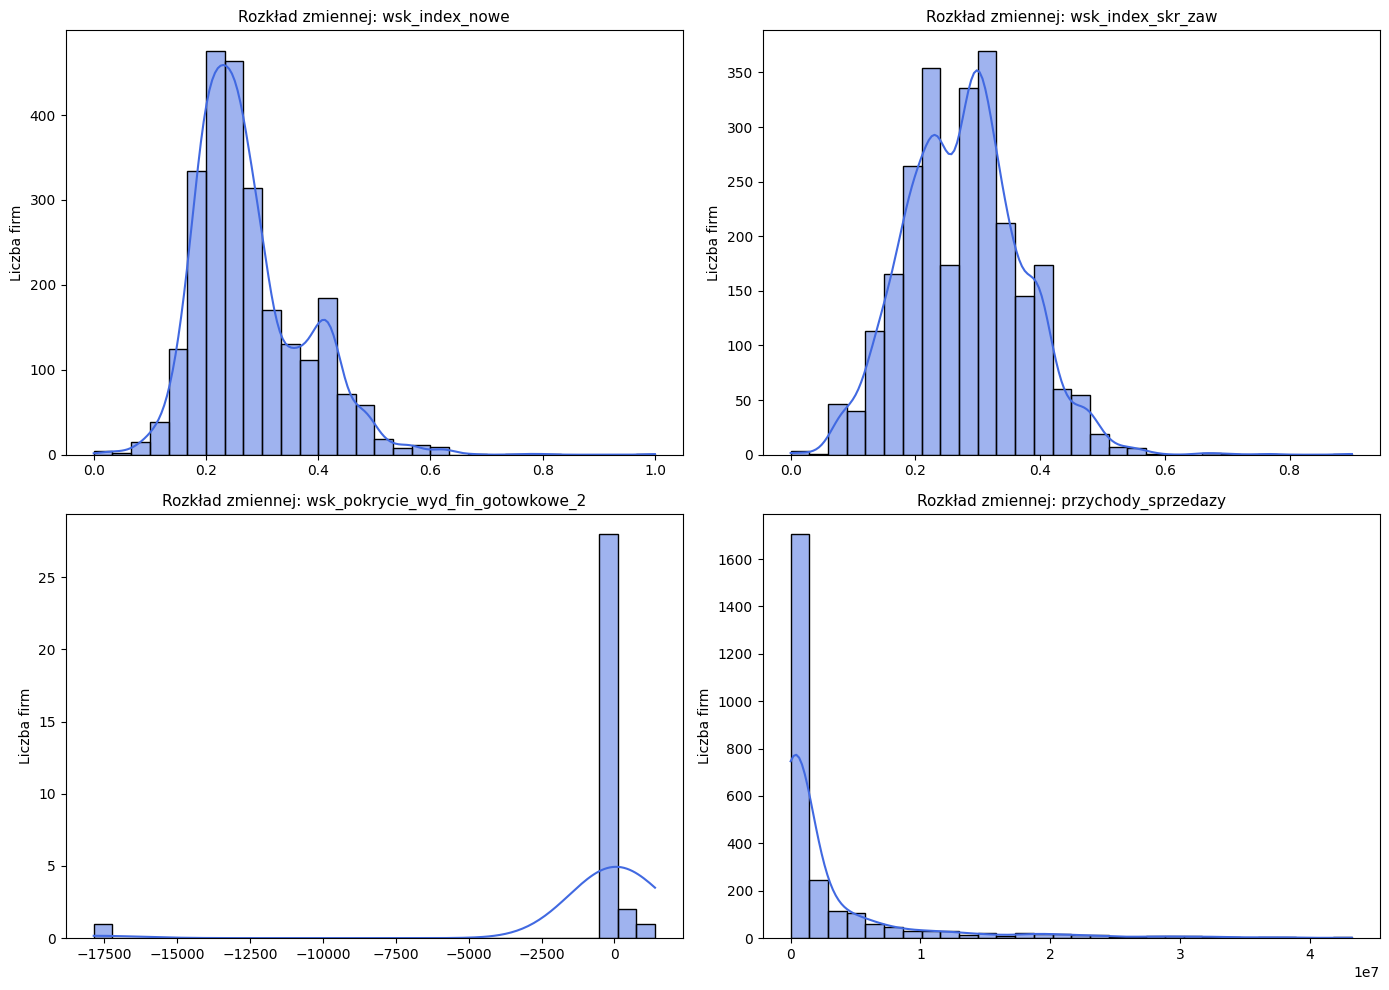

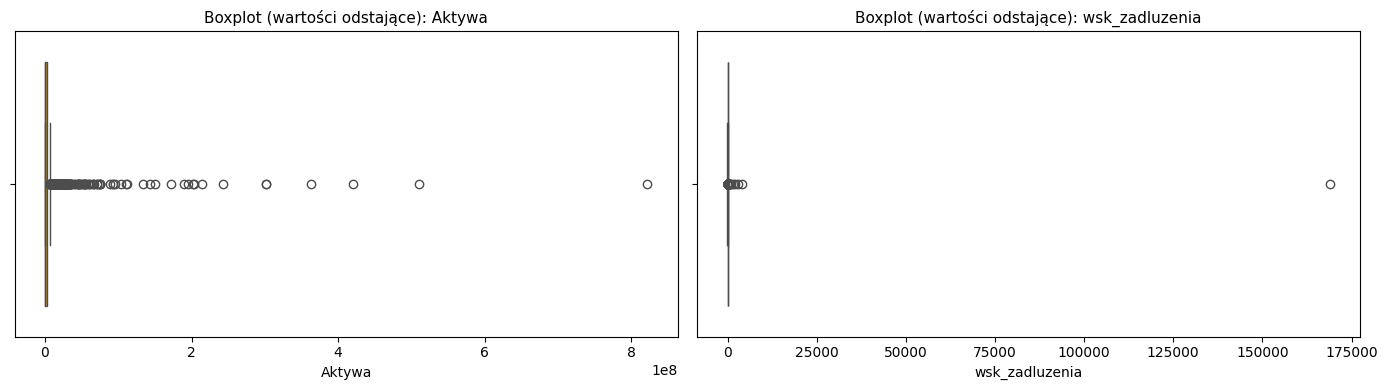

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

wybrane_cechy = [
    'wsk_index_nowe',
    'wsk_index_skr_zaw',
    'wsk_pokrycie_wyd_fin_gotowkowe_2',
    'przychody_sprzedazy'
]

plt.figure(figsize=(14, 10))
for i, col in enumerate(wybrane_cechy, 1):
  plt.subplot(2, 2, i)
  sns.histplot(df_temp[col].dropna(), kde=True, bins=30, color='royalblue')
  plt.title(f'Rozkład zmiennej: {col}', fontsize=11)
  plt.xlabel('')
  plt.ylabel('Liczba firm')

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
for i, col in enumerate(['Aktywa', 'wsk_zadluzenia'], 1):
  plt.subplot(1, 2, i)
  sns.boxplot(x=df_temp[col], color='orange')
  plt.title(f'Boxplot (wartości odstające): {col}', fontsize=11)

plt.tight_layout()
plt.show()

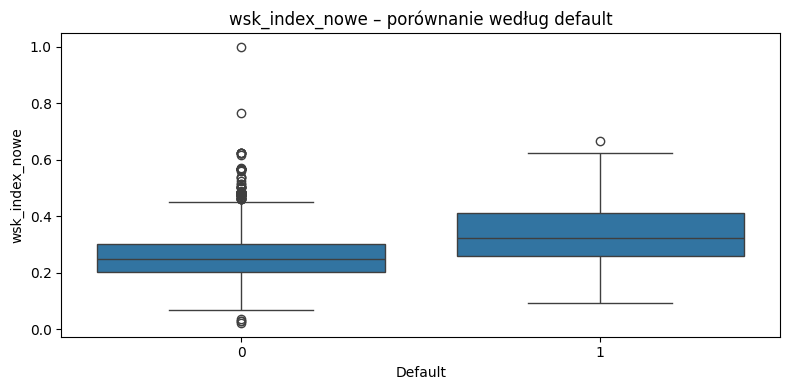

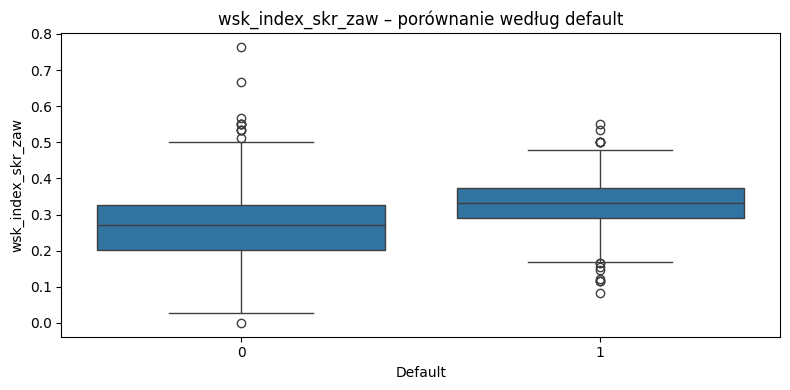

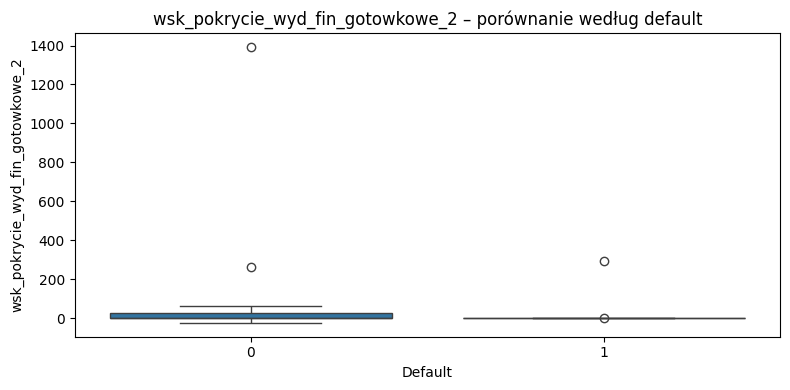

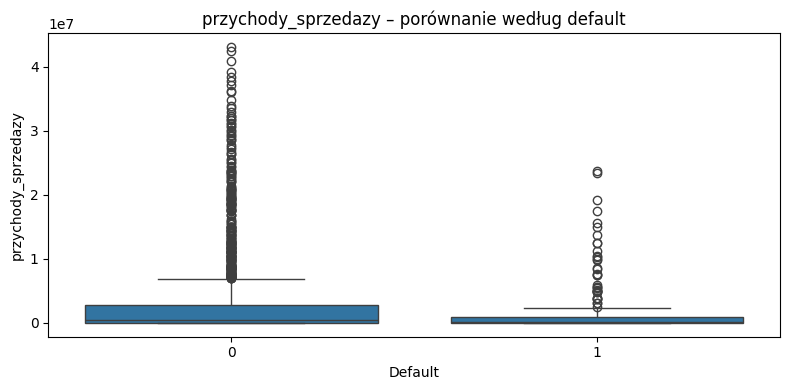

In [14]:
for col in wybrane_cechy:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=pd.DataFrame({
            col: X_train[col],
            "default": y_train
        }),
        x="default",
        y=col
    )

    plt.title(f"{col} – porównanie według default")
    plt.xlabel("Default")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [15]:
import numpy as np
import pandas as pd

num_features = X_temp.select_dtypes(include=[np.number]).columns
corr_matrix = X_temp[num_features].corr().abs()

upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = []
for col in upper_tri.columns:
  high_corr = upper_tri.index[upper_tri[col] > 0.85].tolist()
  for row in high_corr:
    high_corr_pairs.append(
        {'Cecha 1': row, 'Cecha 2': col, 'Korelacja': corr_matrix.loc[row, col]}
    )

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values(
    'Korelacja', ascending=False
)

print(f'Liczba par cech silnie skorelowanych (>0.85): {len(df_high_corr)}')
display(df_high_corr)

Liczba par cech silnie skorelowanych (>0.85): 528


,Cecha 1,Cecha 2,Korelacja
440,wsk_pokrycie_aktywow_kap_stalym,wsk_zast_kapitalu_wlasnego,1.000000
325,wsk_koszty_fin_przychody,wsk_poziom_kosztow_finansowych,1.000000
256,wsk_ebitda_koszty_odsetkowe_2,wsk_ebitda_zobowiazan_odsetki_2,1.000000
247,wsk_ebitda_koszty_odsetkowe_1,wsk_ebitda_zobowiazan_odsetki_1,1.000000
311,wsk_koszty_przychody,wsk_poziom_kosztow_operacyjnych,1.000000
...,...,...,...
49,wsk_Zobowiazania_dlugoterminowe,wsk_stopa_marzy_brutto,0.850135
305,wsk_Zobowiazania_dlugoterminowe,wsk_poziom_kosztow_operacyjnych,0.850134
121,wsk_Zobowiazania_dlugoterminowe,wsk_koszty_przychody,0.850134
132,wsk_Zobowiazania_dlugoterminowe,wsk_stopa_zysku_sprzedaz,0.850132


Usunięcie kolumn stałych oraz dla par identycznych kolumn usunięcie jednej z nich.

In [16]:
kolumny_stale = [
    'szczegolnaFormaPrawna_Symbol',
    'Zobowiazania_dostaw_uslug_pow12m_kapitale',
]
df_temp = df_temp.drop(columns=kolumny_stale, errors='ignore')
df_test = df_test.drop(columns=kolumny_stale, errors='ignore')

columns = X_train.columns.tolist()
columns_to_drop = []
checked_pairs = []

for i in range(len(columns)):
    col1 = columns[i]

    if col1 in columns_to_drop:
        continue

    for j in range(i + 1, len(columns)):
        col2 = columns[j]

        if col2 in columns_to_drop:
            continue

        if X_train[col1].equals(X_train[col2]):
            columns_to_drop.append(col2)
            checked_pairs.append((col1, col2))

X_train = X_train.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)

print("Liczba znalezionych identycznych par:", len(checked_pairs))
print("Liczba usuniętych kolumn:", len(columns_to_drop))

print("\nIdentyczne pary:")
for col1, col2 in checked_pairs:
    print(f"{col1} == {col2} i usunięto: {col2}")

print("\nNowy wymiar X_train:", X_train.shape)
print("Nowy wymiar X_test:", X_test.shape)

Liczba znalezionych identycznych par: 9
Liczba usuniętych kolumn: 9

Identyczne pary:
Naleznosci_dostaw_uslug_pow12m_kapitale == Zobowiazania_dostaw_uslug_pow12m_kapitale i usunięto: Zobowiazania_dostaw_uslug_pow12m_kapitale
wsk_ROS == wsk_rent_sprzedazy i usunięto: wsk_rent_sprzedazy
wsk_zysk_op_zobowiazania == wsk_zysk_operacyjny_zob_1 i usunięto: wsk_zysk_operacyjny_zob_1
wsk_koszty_przychody == wsk_poziom_kosztow_operacyjnych i usunięto: wsk_poziom_kosztow_operacyjnych
wsk_koszty_fin_przychody == wsk_poziom_kosztow_finansowych i usunięto: wsk_poziom_kosztow_finansowych
wsk_koszty_odsetki_przychody == wsk_zadluzenie_gotowka i usunięto: wsk_zadluzenie_gotowka
wsk_udzial_kap_wlasnego_aktywa_1 == wsk_struktura_kap_wlasnego_1 i usunięto: wsk_struktura_kap_wlasnego_1
wsk_ebitda_koszty_odsetkowe_1 == wsk_ebitda_zobowiazan_odsetki_1 i usunięto: wsk_ebitda_zobowiazan_odsetki_1
wsk_ebitda_koszty_odsetkowe_2 == wsk_ebitda_zobowiazan_odsetki_2 i usunięto: wsk_ebitda_zobowiazan_odsetki_2

Nowy 

# Brakujące wartości

,missing_count,missing_pct
RP_przeplywy_operacyjne,2518,98.745098
wsk_pokrycie_wyd_fin_gotowkowe_2,2518,98.745098
wsk_pokrycie_zob_kr_gotowkowe_2,2518,98.745098
wsk_zadluzenia_gotowki_2,2518,98.745098
wsk_akt_generowania_got_2,2518,98.745098
...,...,...
wsk_zob_oprocentowanych_aktywa_rzeczowe,0,0.000000
wsk_struktura_kap_obcego_s,0,0.000000
wsk_zob_s_aktywa_rzeczowe,0,0.000000
wsk_fin_majatku_kapitalem,0,0.000000


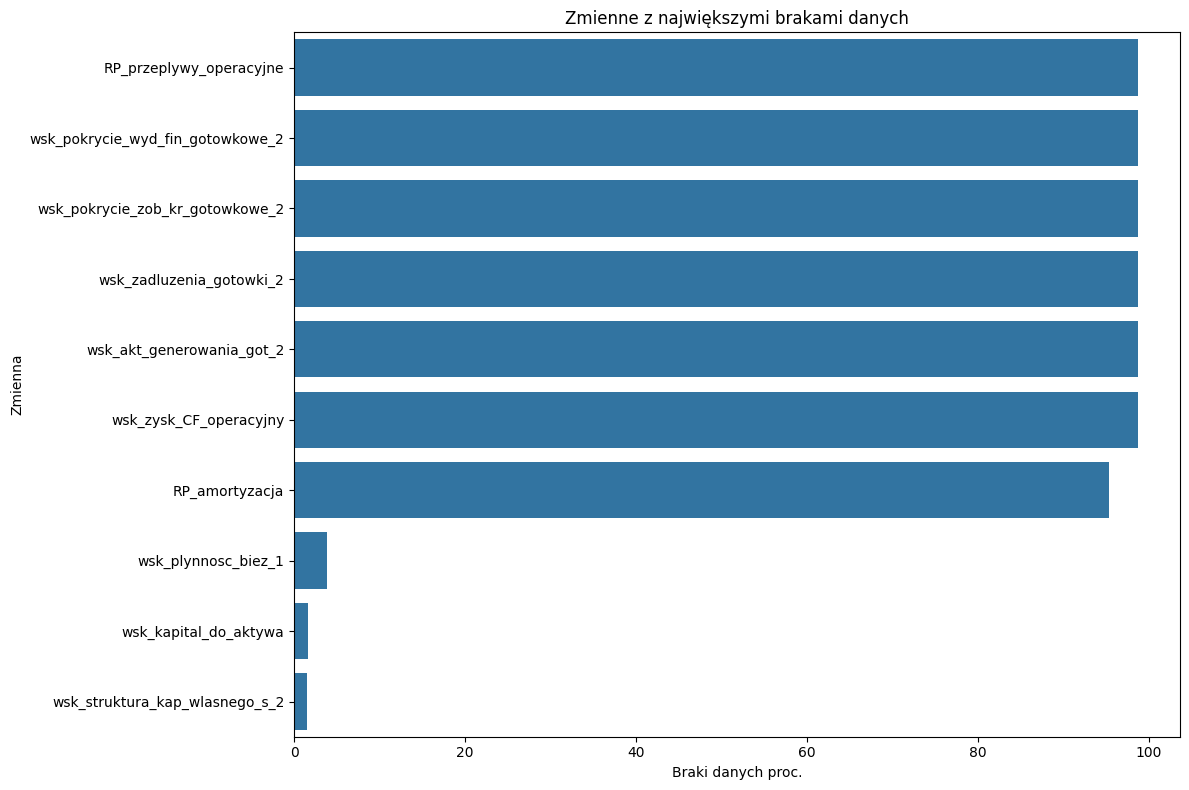

In [17]:
import seaborn as sns

missing_report = pd.DataFrame({
    "missing_count": df_temp.isna().sum(),
    "missing_pct": df_temp.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    "missing_pct",
    ascending=False
)
display(missing_report)

missing_plot = missing_report[
    missing_report["missing_count"] > 0
].head(40)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_plot.reset_index(),
    x="missing_pct",
    y="index"
)

plt.xlabel("Braki danych proc.")
plt.ylabel("Zmienna")
plt.title("Zmienne z największymi brakami danych")
plt.tight_layout()
plt.show()

7 zmiennych ma ponad 90% braków danych.

Tworzymy flagi braków danych, a następnie imputujemy wartości ciągłe medianą wyliczoną na zbiorze treningowym, a dane kategoryczne najczęściej występującą wartością.

In [18]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

df_temp.replace([np.inf, -np.inf], np.nan, inplace=True)
df_test.replace([np.inf, -np.inf], np.nan, inplace=True)

num_na_cols = df_temp.select_dtypes(include=[np.number]).columns
num_na_cols = [c for c in num_na_cols if df_temp[c].isna().sum() > 0]

cat_na_cols = df_temp.select_dtypes(exclude=[np.number]).columns
cat_na_cols = [c for c in cat_na_cols if df_temp[c].isna().sum() > 0]

for col in num_na_cols + cat_na_cols:
    df_temp[f'{col}_missing'] = df_temp[col].isna().astype(int)
    df_test[f'{col}_missing'] = df_test[col].isna().astype(int)

if len(num_na_cols) > 0:
    imput_num = SimpleImputer(strategy='median')
    df_temp[num_na_cols] = imput_num.fit_transform(df_temp[num_na_cols])
    df_test[num_na_cols] = imput_num.transform(df_test[num_na_cols])

if len(cat_na_cols) > 0:
    imput_cat = SimpleImputer(strategy='most_frequent')
    df_temp[cat_na_cols] = imput_cat.fit_transform(df_temp[cat_na_cols])
    df_test[cat_na_cols] = imput_cat.transform(df_test[cat_na_cols])

In [19]:
df_temp.head()

,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,Wartosc_firmy,...,wsk_kapital_do_aktywa_missing,RP_przeplywy_operacyjne_missing,RP_amortyzacja_missing,wsk_akt_generowania_got_2_missing,wsk_pokrycie_wyd_fin_gotowkowe_2_missing,wsk_pokrycie_zob_kr_gotowkowe_2_missing,wsk_zadluzenia_gotowki_2_missing,wsk_plynnosc_biez_1_missing,wsk_zysk_CF_operacyjny_missing,wsk_struktura_kap_wlasnego_s_2_missing
2321,214,4634,-0.012548,0.242812,0.216495,6391,0.00,0.00,0.0,0.0,...,1,1,0,1,1,1,1,1,1,1
2133,214,4773,-0.031386,0.237001,0.156934,1281,5000.00,0.00,0.0,0.0,...,0,1,1,1,1,1,1,1,1,1
509,216,1624,-0.006770,0.215078,0.191038,9210,7232645.47,4034742.22,0.0,0.0,...,0,1,1,1,1,1,1,0,1,0
1316,214,8690,0.071889,0.167413,0.223605,1981,60091.90,0.00,0.0,0.0,...,0,1,1,1,1,1,1,1,1,0
50,214,8211,0.122637,0.422553,0.471359,1531,42424.79,16910.66,0.0,0.0,...,0,1,1,1,1,1,1,0,1,0


# Outlier policy
Obcięcie skrajnych kwantyli na progach wyznaczonych na danych treningowych.

In [20]:
num_cols = df_temp.select_dtypes(
    include=[np.number]
).columns.drop(['default'], errors='ignore')

lower_caps = df_temp[num_cols].quantile(0.01)
upper_caps = df_temp[num_cols].quantile(0.99)

df_temp[num_cols] = df_temp[num_cols].clip(
    lower=lower_caps, upper=upper_caps, axis=1
)
df_test[num_cols] = df_test[num_cols].clip(
    lower=lower_caps, upper=upper_caps, axis=1
)

df_temp.head()

,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,Wartosc_firmy,...,wsk_kapital_do_aktywa_missing,RP_przeplywy_operacyjne_missing,RP_amortyzacja_missing,wsk_akt_generowania_got_2_missing,wsk_pokrycie_wyd_fin_gotowkowe_2_missing,wsk_pokrycie_zob_kr_gotowkowe_2_missing,wsk_zadluzenia_gotowki_2_missing,wsk_plynnosc_biez_1_missing,wsk_zysk_CF_operacyjny_missing,wsk_struktura_kap_wlasnego_s_2_missing
2321,214,4634,-0.012548,0.242812,0.216495,6391,0.00,0.00,0.0,0.0,...,1,1,0,1,1,1,1,1,1,1
2133,214,4773,-0.031386,0.237001,0.156934,1286,5000.00,0.00,0.0,0.0,...,0,1,1,1,1,1,1,1,1,1
509,216,1624,-0.006770,0.215078,0.191038,9210,7232645.47,4034742.22,0.0,0.0,...,0,1,1,1,1,1,1,0,1,0
1316,214,8690,0.071889,0.167413,0.223605,1981,60091.90,0.00,0.0,0.0,...,0,1,1,1,1,1,1,1,1,0
50,214,8211,0.122637,0.422553,0.471359,1531,42424.79,16910.66,0.0,0.0,...,0,1,1,1,1,1,1,0,1,0


# Binning i WoE

Wstępny wybór cech do binningu:
- wsk_zadluzenia
- wsk_plynnosci_biezacej
- wsk_index_nowe
- wsk_index_skr_zaw

Binning i WoE wykonane będą po KFoldingu.

In [21]:
X_temp.to_pickle('X_temp.pkl')
X_test.to_pickle('X_test.pkl')
y_temp.to_pickle('y_temp.pkl')
y_test.to_pickle('y_test.pkl')